# P1 – Network and Louvain communities (fixed version)

Fixes compared with the first notebook:
1. only coordinators and participants (the `role` column)
2. agreed country list (no Turkey; Ukraine, Moldova, Western Balkans added)
3. Newman weight uses the full consortium size
4. CSVs read with `skipinitialspace` and `escapechar`
5. no connected-components consensus: best of 20 Louvain runs + stability

In [19]:
# Imports
import time
from collections import Counter
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import normalized_mutual_info_score as nmi
from sklearn.metrics import adjusted_mutual_info_score as ami

import networkx as nx
from networkx.algorithms.community import modularity
import community as community_louvain
from infomap import Infomap
from sklearn.metrics import normalized_mutual_info_score
from networkx.algorithms import bipartite
from ANS_06_utils import graph_summary
import pyfixest as pf


In [5]:
# 1. Load the data
# Netzschleuder CSVs have spaces after the commas and escaped quotes inside names
df_nodes = pd.read_csv("horizon_europe/nodes.csv", skipinitialspace=True, escapechar="\\", low_memory=False)
df_edges = pd.read_csv("horizon_europe/edges.csv", skipinitialspace=True, escapechar="\\")
df_nodes.columns = [c.lstrip("#").strip() for c in df_nodes.columns]   # '# index' -> 'index'
df_edges.columns = [c.lstrip("#").strip() for c in df_edges.columns]   # '# source' -> 'source'
# in edges.csv: source = organization, target = project

In [6]:
df_nodes.head()

,index,is_project,name,id,latitude,longitude,euroscivoc,acronym,status,start_date,...,grant_doi,keywords,sme,activity_type,city,post_code,country,nuts_code,url,_pos
0,0,1,Full spectrum SOLar Direct Air Capture & conve...,101069359,NaN,NaN,natural sciences/chemical sciences/electrochem...,SolDAC,SIGNED,1661990400,...,10.3030/101069359,"zero-carbon, solar energy, air mining, Negativ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-22.19285885, 116.25605589])"
1,1,1,Artificial PHOTOsynthesis to produce FUELs and...,101069357,NaN,NaN,engineering and technology/environmental engin...,Photo2Fuel,SIGNED,1661990400,...,10.3030/101069357,solar energy; bacteria; archaea; solar fuels; ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-23.54534475, 117.30806949])"
2,2,1,Bridging Organizations and marginalized commun...,101069586,NaN,NaN,social sciences/sociology/governance|social sc...,BOLSTER,SIGNED,1661990400,...,10.3030/101069586,Transition strategies; Participation; Marginal...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-18.23962287, 118.80845353])"
3,3,1,NCPS NETwork for the GREEN transition in clima...,101069604,NaN,NaN,NaN,GREENET,SIGNED,1656633600,...,10.3030/101069604,"Competence development, Capacity building, CL5...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-27.77547463, 109.60801029])"
4,4,1,"Social Sciences and Humanities for Climate, En...",101069529,NaN,NaN,social sciences/economics and business/economi...,SSH CENTRE,SIGNED,1661990400,...,10.3030/101069529,Transitions; Transdisciplinary; Epistemic cult...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"array([-26.48000805, 108.76182656])"


In [7]:
# 2. Filters
EU27 = ["AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI", "FR", "DE", "EL", "HU", "IE",
        "IT", "LV", "LT", "LU", "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"]
european_countries = EU27 + ["NO", "IS", "LI", "CH", "UK",            # EFTA + UK
                             "AL", "BA", "ME", "MK", "RS", "XK",      # Western Balkans
                             "UA", "MD", "FO", "VA", "MC", "GI"]      # other European
valid_funding_schemes = ["HORIZON-RIA", "HORIZON-IA", "HORIZON-JU-RIA", "HORIZON-JU-IA"]
valid_activity_types = ["HES", "REC"]
valid_roles = ["coordinator", "participant"]

projects = df_nodes[(df_nodes["is_project"] == 1)
                    & df_nodes["funding_scheme"].isin(valid_funding_schemes)]
orgs = df_nodes[(df_nodes["is_project"] == 0)
                & df_nodes["activity_type"].isin(valid_activity_types)
                & df_nodes["country"].isin(european_countries)]

# coordinators and participants of the kept projects (all organization types and countries)
memberships = df_edges[df_edges["role"].isin(valid_roles)
                       & df_edges["target"].isin(projects["index"])]

# Newman weight needs the real consortium size: all coordinators + participants of the project
consortium_size = memberships.groupby("target")["source"].nunique()

# keep European universities and research organizations with at least 3 projects
memberships = memberships[memberships["source"].isin(orgs["index"])]
n_projects = memberships.groupby("source")["target"].nunique()
final_org_ids = set(n_projects[n_projects >= 3].index)
memberships = memberships[memberships["source"].isin(final_org_ids)]

print(f"Organizations: {len(final_org_ids)}, projects: {memberships['target'].nunique()}")

Organizations: 1655, projects: 4856


In [8]:
# 3. Newman-weighted projection: each project adds 1/(n-1) to every pair of its members
org_net = nx.Graph()
for project, members in memberships.groupby("target")["source"]:
    members = sorted(set(members))
    if len(members) < 2:                    # a project with one kept member adds no edge
        continue
    w = 1.0 / (consortium_size[project] - 1)
    for u, v in itertools.combinations(members, 2):
        if org_net.has_edge(u, v):
            org_net[u][v]["weight"] += w
            org_net[u][v]["n_joint"] += 1
        else:
            org_net.add_edge(u, v, weight=w, n_joint=1)

for u, v, d in org_net.edges(data=True):
    d["dist"] = 1.0 / d["weight"]          # distance for betweenness (P2)

graph_summary(org_net)

Directed: False
Weighted: True
Nodes: 1655
Edges: 70779
Density: 0.05171314071535817
Number of components: 1


In [9]:
# 4. Node labels: name, country, type, projects, coordinated projects, topic
def second_level_fields(s):
    """'natural sciences/chemical sciences/electrochemistry|...' -> ['natural sciences', ...]"""
    if not isinstance(s, str):
        return []
    return list({x.split("/")[1] for x in s.split("|") if x.count("/") >= 1})


project_fields = projects.set_index("index")["euroscivoc"].apply(second_level_fields)
fields_long = memberships.assign(field=memberships["target"].map(project_fields)).explode("field")
topic = fields_long.dropna(subset=["field"]).groupby("source")["field"].agg(lambda s: s.mode()[0])
n_coord = memberships[memberships["role"] == "coordinator"].groupby("source").size()

info = orgs.set_index("index")
labels = pd.DataFrame({
    "name": info["name"],
    "country": info["country"],
    "org_type": info["activity_type"],
    "n_projects": n_projects,
    "n_coordinated": n_coord,
    "topic": topic,
}).loc[list(org_net.nodes())]
labels["n_coordinated"] = labels["n_coordinated"].fillna(0).astype(int)
labels["topic"] = labels["topic"].fillna("unknown")
nx.set_node_attributes(org_net, labels.to_dict("index"))
labels.head()

,name,country,org_type,n_projects,n_coordinated,topic
23957,THE UNIVERSITY COURT OF THE UNIVERSITY OF ST A...,UK,HES,14.0,1,biological sciences
23958,FUNDACIO INSTITUT DE RECERCA EN ENERGIA DE CAT...,ES,REC,32.0,2,environmental engineering
23959,UNIVERSIDAD DE LLEIDA,ES,HES,9.0,0,environmental engineering
23960,CONSIGLIO NAZIONALE DELLE RICERCHE,IT,REC,279.0,70,computer and information sciences
23961,THE UNIVERSITY OF EDINBURGH,UK,HES,61.0,57,computer and information sciences


In [10]:
# 5. Louvain: 20 runs, keep the one with the highest modularity
runs = [community_louvain.best_partition(org_net, weight="weight", random_state=s) for s in range(20)]
Q = [community_louvain.modularity(r, org_net, weight="weight") for r in runs]
best_seed = int(np.argmax(Q))
partition = runs[best_seed]
labels["community"] = pd.Series(partition)

print(f"Best run: seed {best_seed}, {len(set(partition.values()))} communities, Q = {Q[best_seed]:.4f}")
print(f"Modularity over 20 runs: mean {np.mean(Q):.4f}, min {min(Q):.4f}, max {max(Q):.4f}")

Best run: seed 15, 5 communities, Q = 0.2459
Modularity over 20 runs: mean 0.2438, min 0.2416, max 0.2459


In [11]:
# 6. Stability: compare all pairs of runs
nodes_sorted = sorted(org_net.nodes())
vecs = [[r[n] for n in nodes_sorted] for r in runs]
pairs = list(itertools.combinations(vecs, 2))
print(f"Mean NMI between runs: {np.mean([nmi(a, b) for a, b in pairs]):.3f}")
print(f"Mean AMI between runs: {np.mean([ami(a, b) for a, b in pairs]):.3f}")

Mean NMI between runs: 0.682
Mean AMI between runs: 0.681


In [12]:
# 7. Resolution sweep (robustness): 10 runs per resolution
rows = []
for res in [0.5, 0.75, 1.0, 1.25, 1.5]:
    rr = [community_louvain.best_partition(org_net, weight="weight", resolution=res, random_state=s)
          for s in range(10)]
    vv = [[r[n] for n in nodes_sorted] for r in rr]
    rows.append({
        "resolution": res,
        "communities (median)": int(np.median([len(set(r.values())) for r in rr])),
        "modularity (mean)": round(np.mean([community_louvain.modularity(r, org_net) for r in rr]), 3),
        "stability AMI": round(np.mean([ami(a, b) for a, b in itertools.combinations(vv, 2)]), 3),
    })
sweep = pd.DataFrame(rows)
sweep

,resolution,communities (median),modularity (mean),stability AMI
0,0.50,240,0.087,0.201
1,0.75,7,0.232,0.610
2,1.00,5,0.244,0.675
3,1.25,12,0.225,0.621
4,1.50,21,0.200,0.586


In [13]:
# 8. Community profiles: size, top topics, top countries
profiles = []
for c, grp in labels.groupby("community"):
    top_topics = grp["topic"].value_counts(normalize=True).head(3)
    top_countries = grp["country"].value_counts(normalize=True).head(3)
    profiles.append({
        "community": c,
        "size": len(grp),
        "top topics": ", ".join(f"{t} {v:.0%}" for t, v in top_topics.items()),
        "top countries": ", ".join(f"{t} {v:.0%}" for t, v in top_countries.items()),
        "n countries": grp["country"].nunique(),
    })
profiles = pd.DataFrame(profiles).sort_values("size", ascending=False)
profiles

,community,size,top topics,top countries,n countries
1,1,575,"computer and information sciences 31%, environ...","ES 18%, DE 11%, IT 9%",32
2,2,474,"clinical medicine 24%, computer and informatio...","DE 14%, ES 11%, IT 10%",32
4,4,346,"agriculture, forestry, and fisheries 41%, biol...","DE 15%, ES 13%, IT 7%",33
0,0,257,"earth and related environmental sciences 29%, ...","FR 17%, DE 11%, IT 9%",31
3,3,3,"biological sciences 67%, environmental enginee...","IT 33%, FR 33%, PL 33%",3


In [14]:
# 9. What organizes the communities? AMI with topic / country / type vs shuffled labels
rng = np.random.default_rng(0)
comm = labels["community"].values
rows = []
for col in ["topic", "country", "org_type"]:
    lab = labels[col].values
    real = ami(lab, comm) # maybe we should reason why don't we use NMI
    shuffled = [ami(rng.permutation(lab), comm) for _ in range(200)]
    rows.append({"label": col, "AMI": round(real, 3),
                 "shuffled mean": round(np.mean(shuffled), 4),
                 "shuffled 99th pct": round(np.percentile(shuffled, 99), 4)})
organizing = pd.DataFrame(rows)
organizing         

,label,AMI,shuffled mean,shuffled 99th pct
0,topic,0.190,0.0001,0.0049
1,country,0.016,0.0003,0.0052
2,org_type,0.008,0.0000,0.0031


In [15]:
# 10. Niche communities: Louvain again inside each big community
niche = {}
for c, grp in labels.groupby("community"):
    sub = org_net.subgraph(grp.index)
    if sub.number_of_edges() == 0:
        niche.update({n: f"{c}.0" for n in grp.index})
        continue
    p = community_louvain.best_partition(sub, weight="weight", random_state=0)
    niche.update({n: f"{c}.{k}" for n, k in p.items()})
labels["niche"] = pd.Series(niche)
print(f"{labels['niche'].nunique()} niche communities")

26 niche communities


In [16]:
# 11. Save files for P2, P3 and P4
nx.to_pandas_edgelist(org_net).to_csv("network_edges.csv", index=False)       # source, target, weight, n_joint, dist
labels.rename_axis("org").to_csv("communities.csv")                            # labels + community + niche
profiles.to_csv("community_profiles.csv", index=False)
organizing.to_csv("ami_topic_country_type.csv", index=False)
sweep.to_csv("resolution_sweep.csv", index=False)

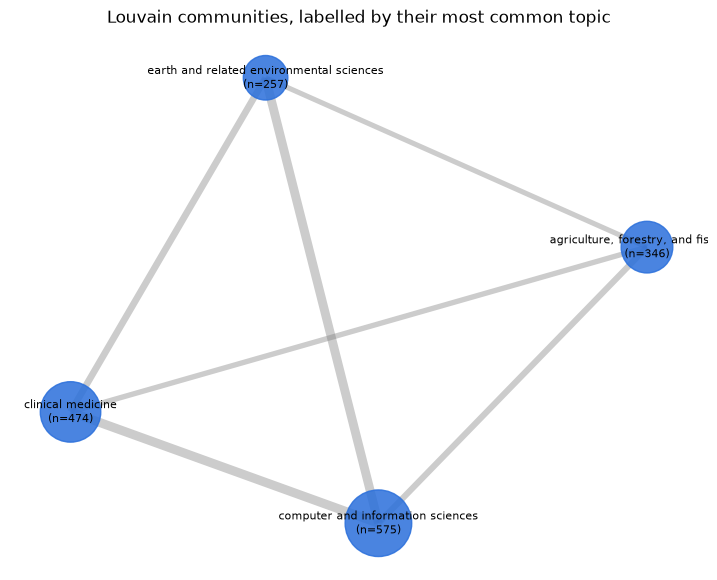

In [17]:
# 12. Figure: one node per community (instead of the full hairball)
C = nx.Graph()
for c, grp in labels.groupby("community"):
    if len(grp) >= 10:                      # skip tiny communities
        C.add_node(c, size=len(grp), topic=grp["topic"].value_counts().index[0])
for u, v, d in org_net.edges(data=True):
    cu, cv = partition[u], partition[v]
    if cu != cv and cu in C and cv in C:
        old = C[cu][cv]["weight"] if C.has_edge(cu, cv) else 0
        C.add_edge(cu, cv, weight=old + d["weight"])

pos = nx.spring_layout(C, weight="weight", seed=1)
wmax = max(d["weight"] for _, _, d in C.edges(data=True))
plt.figure(figsize=(9, 7))
nx.draw_networkx_edges(C, pos, width=[0.5 + 6 * d["weight"] / wmax for _, _, d in C.edges(data=True)],
                       alpha=0.4, edge_color="gray")
nx.draw_networkx_nodes(C, pos, node_size=[4 * C.nodes[c]["size"] for c in C], node_color="#2a6fdb", alpha=0.85)
nx.draw_networkx_labels(C, pos, {c: f"{C.nodes[c]['topic']}\n(n={C.nodes[c]['size']})" for c in C}, font_size=8)
plt.title("Louvain communities, labelled by their most common topic")
plt.axis("off")
plt.show()

NameError: name 'cl_louvain' is not defined

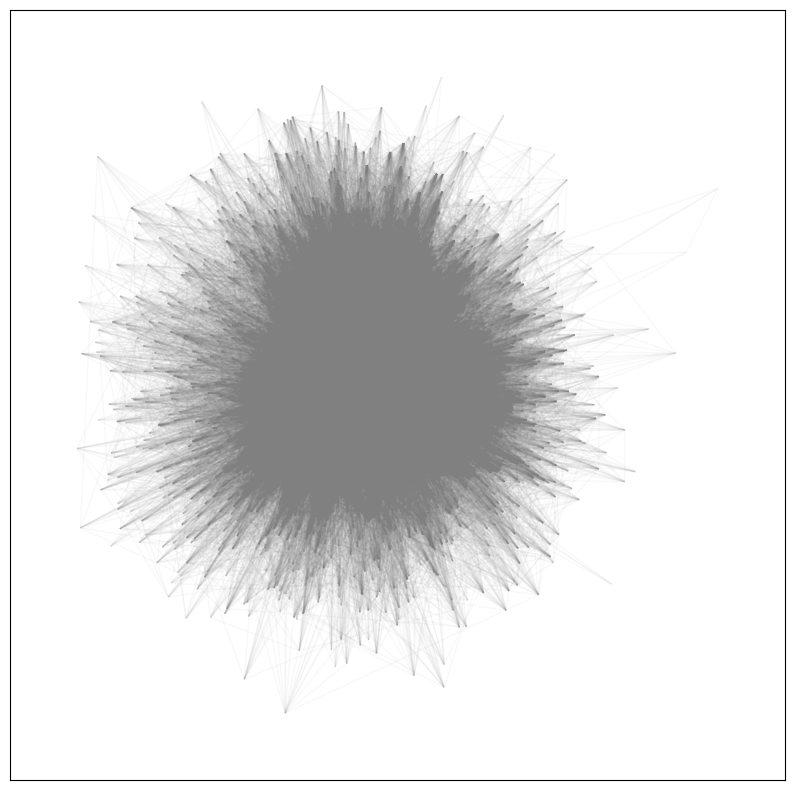

In [18]:
plt.figure(figsize=(10, 10))

pos_karate = nx.spring_layout(org_net, k=0.5, seed=2)

nx.draw_networkx_edges(org_net, pos_karate, alpha=0.05, edge_color="gray")
nx.draw_networkx_nodes(
    org_net,
    pos_karate,
    node_size=35,
    node_color=list(cl_louvain.values()),
    cmap=plt.cm.Set3,
)

plt.title("Louvain communities on the organization network")
plt.axis("off") 
plt.show()

**EU funding per organization**

In [21]:
labels["funding_eur"] = memberships.groupby("source")["ec_contribution"].sum()
labels.loc[labels["country"].isin(["CH", "UK"]), "funding_eur"] = np.nan   # missing, not zero
labels["funding_eur"].describe()

count    1.504000e+03
mean     8.535683e+06
std      2.147403e+07
min      0.000000e+00
25%      1.208838e+06
50%      2.625389e+06
75%      6.839933e+06
max      4.105584e+08
Name: funding_eur, dtype: float64

**Centrality measures**

Degree, strength, eigenvector, closeness

In [23]:
cent = pd.DataFrame(index=list(org_net.nodes()))

cent["degree"] = pd.Series(dict(org_net.degree()))                     # number of partners
cent["strength"] = pd.Series(dict(org_net.degree(weight="weight")))     # sum of tie weights
cent["eigenvector"] = pd.Series(nx.eigenvector_centrality_numpy(org_net, weight="weight"))
cent["closeness"] = pd.Series(nx.closeness_centrality(org_net, distance="dist"))
cent.describe()

,degree,strength,eigenvector,closeness
count,1655.000000,1655.000000,1655.000000,1655.000000
mean,85.533535,7.906553,0.011981,0.086499
std,100.502269,13.293654,0.021470,0.022614
min,4.000000,0.419314,0.000122,0.029915
25%,25.000000,1.880120,0.002556,0.070299
50%,46.000000,3.368598,0.004828,0.084064
75%,103.000000,8.026208,0.011261,0.100454
max,852.000000,183.300509,0.295910,0.155393


Betweenness - weight="dist": strong ties count as short paths

In [24]:
cent["betweenness"] = pd.Series(nx.betweenness_centrality(org_net, weight="dist"))
cent["betweenness"].describe()

count    1655.000000
mean        0.001581
std         0.014150
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000018
max         0.467056
Name: betweenness, dtype: float64

Local clustering - do my partners know each other?
- 1 = all my partners work with each other (closed circle, no brokerage)
- 0 = none of my partners work with each other (I am the only link between them = broker)

In [25]:
cent["clustering"] = pd.Series(nx.clustering(org_net))
cent["clustering"].describe()

count    1655.000000
mean        0.468308
std         0.143953
min         0.111076
25%         0.358480
50%         0.460876
75%         0.560247
max         1.000000
Name: clustering, dtype: float64

How similar are the centralities? (Spearman = rank correlation)
Expectation: degree, strength and eigenvector are almost the same ranking (they all measure "size"). Betweenness should be the odd one out - it measures position, not size.

In [26]:
cent.corr(method="spearman").round(2)

,degree,strength,eigenvector,closeness,betweenness,clustering
degree,1.00,0.92,0.87,0.66,0.65,-0.64
strength,0.92,1.00,0.94,0.81,0.74,-0.74
eigenvector,0.87,0.94,1.00,0.87,0.68,-0.65
closeness,0.66,0.81,0.87,1.00,0.66,-0.58
betweenness,0.65,0.74,0.68,0.66,1.00,-0.70
clustering,-0.64,-0.74,-0.65,-0.58,-0.70,1.00


Top 10 for each measure

In [31]:
top10 = pd.DataFrame({
    col: labels.loc[cent[col].sort_values(ascending=False).head(10).index, "name"].str[:40].values
    for col in ["degree", "strength", "eigenvector", "betweenness"]
})
top10["lowest clustering"] = labels.loc[cent["clustering"].sort_values().head(10).index, "name"].str[:40].values
top10.index = range(1, 11)
top10

,degree,strength,eigenvector,betweenness,lowest clustering
1,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DE,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DE,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DE,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DE,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG DE
2,CONSIGLIO NAZIONALE DELLE RICERCHE,CONSIGLIO NAZIONALE DELLE RICERCHE,COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX,AGENCIA ESTATAL CONSEJO SUPERIOR DE INVE,CONSIGLIO NAZIONALE DELLE RICERCHE
3,AGENCIA ESTATAL CONSEJO SUPERIOR DE INVE,AGENCIA ESTATAL CONSEJO SUPERIOR DE INVE,CONSIGLIO NAZIONALE DELLE RICERCHE,CONSIGLIO NAZIONALE DELLE RICERCHE,AGENCIA ESTATAL CONSEJO SUPERIOR DE INVE
4,COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX,COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX,AGENCIA ESTATAL CONSEJO SUPERIOR DE INVE,COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX,ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS
5,CENTRE NATIONAL DE LA RECHERCHE SCIENTIF,CENTRE NATIONAL DE LA RECHERCHE SCIENTIF,CENTRE NATIONAL DE LA RECHERCHE SCIENTIF,CENTRE NATIONAL DE LA RECHERCHE SCIENTIF,ALMA MATER STUDIORUM - UNIVERSITA DI BOL
6,KATHOLIEKE UNIVERSITEIT LEUVEN,KATHOLIEKE UNIVERSITEIT LEUVEN,TECHNISCHE UNIVERSITEIT DELFT,TECHNISCHE UNIVERSITEIT DELFT,COMMISSARIAT A L ENERGIE ATOMIQUE ET AUX
7,AARHUS UNIVERSITET,DANMARKS TEKNISKE UNIVERSITET,DANMARKS TEKNISKE UNIVERSITET,WAGENINGEN UNIVERSITY,KATHOLIEKE UNIVERSITEIT LEUVEN
8,DANMARKS TEKNISKE UNIVERSITET,TECHNISCHE UNIVERSITEIT DELFT,TEKNOLOGIAN TUTKIMUSKESKUS VTT OY,KATHOLIEKE UNIVERSITEIT LEUVEN,TECHNISCHE UNIVERSITEIT DELFT
9,ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS,ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS,DEUTSCHES ZENTRUM FUR LUFT - UND RAUMFAH,ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS,DANMARKS TEKNISKE UNIVERSITET
10,ALMA MATER STUDIORUM - UNIVERSITA DI BOL,AARHUS UNIVERSITET,ETHNIKO KENTRO EREVNAS KAI TECHNOLOGIKIS,DANMARKS TEKNISKE UNIVERSITET,AARHUS UNIVERSITET


**Giants and brokers**

**Giants:** the 50 organizations with the most partners (highest degree).

**Brokers (H1):** organizations with much more betweenness than expected.
Big organizations naturally have high betweenness (they are on many paths simply because they
have many partners), and coordinators sit in every tie of their projects. So we ask:
given its size and its coordinator role, does this organization have unusually high betweenness?

We answer with a regression:

log(betweenness) = b0 + b1·log(degree) + b2·log(1 + coordinated projects) + b3·share coordinated + error

The residual (error) is the part of betweenness that size and coordination do NOT explain.
Brokers = top 5% of residuals. We only use organizations with ≥ 10 projects, because the
betweenness of very small organizations is unstable.

In [ ]:
#Giants
data = labels.join(cent)
data["rank_degree"] = data["degree"].rank(ascending=False)
data["rank_betweenness"] = data["betweenness"].rank(ascending=False)
data["giant"] = data["rank_degree"] <= 50

In [35]:
#Brokers: regression residuals
data["coord_share"] = data["n_coordinated"] / data["n_projects"]
reg = data[data["n_projects"] >= 10].copy()

reg["log_betweenness"] = np.log(reg["betweenness"] + 1e-7)
reg["log_degree"] = np.log(reg["degree"])
reg["log_coordinated"] = np.log1p(reg["n_coordinated"])

m1 = pf.feols("log_betweenness ~ log_degree", data=reg)                                  
m2 = pf.feols("log_betweenness ~ log_degree + log_coordinated + coord_share", data=reg)    
pf.etable([m1, m2])   

GT(_tbl_data=  __index_level_0__ __index_level_1__                        0  \
0              coef        log_degree    3.832*** <br> (0.169)   
1              coef   log_coordinated                            
2              coef       coord_share                            
3              coef         Intercept  -28.449*** <br> (0.827)   
4             stats      Observations                      656   
5             stats                R²                    0.441   

                         1  
0    2.009*** <br> (0.241)  
1    2.389*** <br> (0.239)  
2   -7.706*** <br> (0.941)  
3  -21.673*** <br> (1.033)  
4                      656  
5                    0.516  , _body=<great_tables._gt_data.Body object at 0x000001D65807FF50>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label='(1)', column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label='(2)', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001D655690230>, _spanners=Spanners([SpannerInfo(spanner_id='log_betweenness', spanner_level=1, spanner_label='log_betweenness', spanner_units=None, spanner_pattern=None, vars=['0', '1'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001D66622B620>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001D655692540>, _source_notes=['Significance levels: * p < 0.05, ** p < 0.01, *** p < 0.001. Format of coefficient cell: Coefficient   (Std. Error)'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001D655691580>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', ty

In [79]:
#Residual = "extra" betweenness
reg["residual"] = m2.resid()
reg["broker"] = reg["residual"].rank(ascending=False) <= 50

data["residual"] = reg["residual"]
data["broker"] = reg["broker"].reindex(data.index).fillna(False).astype(bool)

print(f"Brokers: {data['broker'].sum()} (organizations with >= 10 projects, top 5% residual)")
print(f"Brokers that are also giants: {(data['broker'] & data['giant']).sum()}")

# the brokers, strongest first
cols = ["name", "country", "org_type", "n_projects", "n_coordinated", "rank_degree",
        "rank_betweenness", "residual", "topic"]
data[data["broker"]].sort_values("residual", ascending=False)[cols].round(2).head(10)

Brokers: 50 (organizations with >= 10 projects, top 5% residual)
Brokers that are also giants: 0


,name,country,org_type,n_projects,n_coordinated,rank_degree,rank_betweenness,residual,topic
27629,ECOLE NATIONALE DE L AVIATION CIVILE,FR,HES,18,18,1270.0,209.0,9.23,social geography
27624,EUROCONTROL - EUROPEAN ORGANISATION FOR THE SA...,BE,REC,48,48,869.0,66.0,7.46,social geography
25793,RTDS - VEREIN ZUR FORDERUNG DER KOMMUNIKATION ...,AT,REC,11,0,992.0,270.0,6.91,"agriculture, forestry, and fisheries"
41013,LIVERPOOL SCHOOL OF TROPICAL MEDICINE,UK,HES,11,0,1294.5,307.0,6.57,basic medicine
35486,SIEC BADAWCZA LUKASIEWICZ-INSTYTUT LOTNICTWA,PL,REC,10,3,887.5,211.5,6.38,mechanical engineering
31008,VDEH-BETRIEBSFORSCHUNGSINSTITUT GMBH,DE,REC,14,1,887.5,177.0,6.36,environmental engineering
28022,IHP GMBH - LEIBNIZ INSTITUTE FOR HIGH PERFORMA...,DE,REC,13,1,869.0,221.0,6.23,"electrical engineering, electronic engineering..."
24330,UNIVERSITE MARIE ET LOUIS PASTEUR,FR,HES,10,1,742.5,211.5,6.08,chemical sciences
26279,CEU GMBH,AT,HES,13,0,701.5,271.0,5.91,political sciences
24494,INSTITUT PASTEUR,FR,REC,24,0,228.0,91.0,5.90,biological sciences


**Comparison of Giants and Brokers**

In [53]:
#Profile table
data["group"] = np.where(data["giant"], "giants",
                         np.where(data["broker"], "brokers", "everyone else"))

profile = data.groupby("group").agg(
    organizations=("name", "size"),
    median_projects=("n_projects", "median"),
    median_partners=("degree", "median"),
    median_funding_eur_m=("funding_eur", lambda x: x.median() / 1e6),
    coordinator_share=("coord_share", "mean"),
    share_research_orgs=("org_type", lambda x: (x == "REC").mean()),
    mean_clustering=("clustering", "mean"),
).round(3)
profile

,organizations,median_projects,median_partners,median_funding_eur_m,coordinator_share,share_research_orgs,mean_clustering
group,,,,,,,
brokers,50,15.5,81.5,7.302,0.181,0.580,0.386
everyone else,1555,6.0,44.0,2.398,0.201,0.554,0.480
giants,50,124.5,436.5,71.134,0.174,0.380,0.201


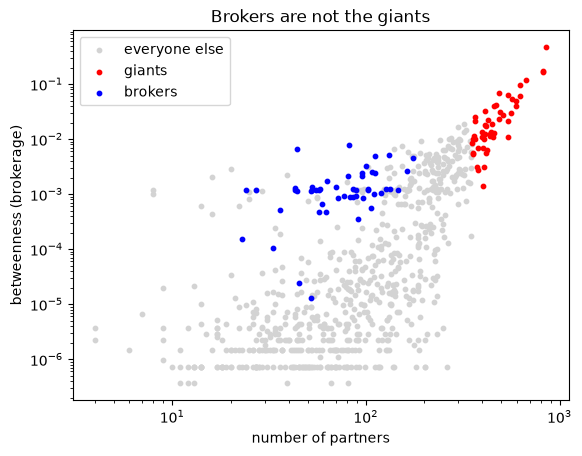

In [54]:
# partners vs brokerage, giants and brokers highlighted
d = data[data["betweenness"] > 0]

for grp, color in [("everyone else", "lightgray"), ("giants", "red"), ("brokers", "blue")]:
    g = d[d["group"] == grp]
    plt.scatter(g["degree"], g["betweenness"], color=color, s=10, label=grp)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("number of partners")
plt.ylabel("betweenness (brokerage)")
plt.title("Brokers are not the giants")
plt.legend()
plt.show()

**Robustness check**: remove giants first, brokers first, or random organizations
- Core network = only ties with at least 2 shared projects (the lasting collaborations) - robustness check
- On the full network almost nothing falls apart, because it is so dense

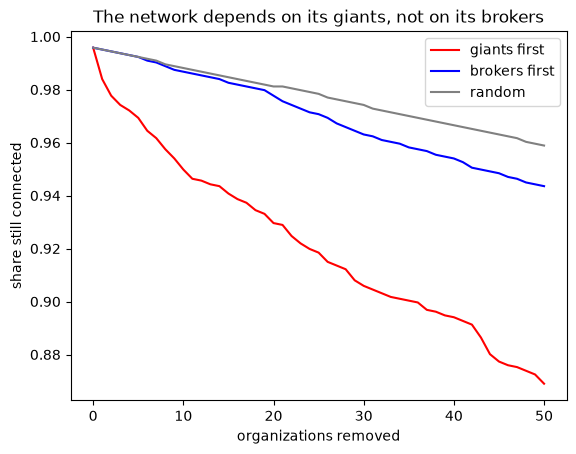

After removing 50: giants 0.869 | brokers 0.944 | random 0.959


In [73]:
core = nx.Graph()
core.add_edges_from((u, v) for u, v, d in org_net.edges(data=True) if d["n_joint"] >= 2)
n = core.number_of_nodes()

def share_after(remove):
    H = core.copy()
    H.remove_nodes_from(remove)
    return len(max(nx.connected_components(H), key=len)) / n

giants_first = sorted(core.nodes(), key=lambda x: cent.loc[x, "degree"], reverse=True)
brokers_first = [o for o in data["residual"].sort_values(ascending=False).dropna().index if o in core]
random_order = list(np.random.default_rng(1).permutation(list(core.nodes())))

steps = range(0, 51)
giants_curve = [share_after(giants_first[:k]) for k in steps]
brokers_curve = [share_after(brokers_first[:k]) for k in steps]
random_curve = [share_after(random_order[:k]) for k in steps]

plt.plot(steps, giants_curve, color="red", label="giants first")
plt.plot(steps, brokers_curve, color="blue", label="brokers first")
plt.plot(steps, random_curve, color="gray", label="random")
plt.xlabel("organizations removed")
plt.ylabel("share still connected")
plt.title("The network depends on its giants, not on its brokers")
plt.legend()
plt.show()

print(f"After removing {50}: giants {giants_curve[-1]:.3f} | brokers {brokers_curve[-1]:.3f} | "
      f"random {random_curve[-1]:.3f}")

**P2.6 Does brokerage go with success?**
- Success = EU funding per project (log), ≥ 10 projects
- model 1: size only, model 2: size + brokerage
- Country fixed effects and country-clustered errors, because EU funding pays salaries, which differ by country

In [ ]:
succ = reg[reg["funding_eur"] > 0].copy()
succ["log_funding_per_project"] = np.log(succ["funding_eur"] / succ["n_projects"])

m3 = pf.feols("log_funding_per_project ~ log_degree | country", data=succ, vcov={"CRV1": "country"})
m4 = pf.feols("log_funding_per_project ~ log_degree + log_betweenness | country", data=succ,
              vcov={"CRV1": "country"})
pf.etable([m3, m4])

c:\Users\Asus\anaconda3\envs\ans-env\Lib\site-packages\pyfixest\estimation\formula\model_matrix.py:151: UserWarning: 3 singleton fixed effect(s) dropped from the model.
  warnings.warn(
c:\Users\Asus\anaconda3\envs\ans-env\Lib\site-packages\pyfixest\estimation\formula\model_matrix.py:151: UserWarning: 3 singleton fixed effect(s) dropped from the model.
  warnings.warn(


GT(_tbl_data=  __index_level_0__ __index_level_1__                     0  \
0              coef        log_degree  0.098** <br> (0.028)   
1              coef   log_betweenness                         
2                fe           country                     x   
3             stats      Observations                   572   
4             stats                R²                 0.242   

                       1  
0    -0.002 <br> (0.038)  
1  0.026*** <br> (0.006)  
2                      x  
3                    572  
4                   0.27  , _body=<great_tables._gt_data.Body object at 0x000001D655B495B0>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label='(1)', column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label='(2)', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001D655B485C0>, _spanners=Spanners([SpannerInfo(spanner_id='log_funding_per_project', spanner_level=1, spanner_label='log_funding_per_project', spanner_units=None, spanner_pattern=None, vars=['0', '1'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001D655B4A510>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001D655B4A990>, _source_notes=['Significance levels: * p < 0.05, ** p < 0.01, *** p < 0.001. Format of coefficient cell: Coefficient   (Std. Error)'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x000001D655B4BE60>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value=